# Task 2: PPO

This notebook runs independently and delegates experiments to task-specific Python modules.
The CPU diagnostics below validate mathematics/aggregation using explicitly labeled hand-authored fixtures;
they are **not** trained-model/course results. Actual course results are loaded from disk in the final cells.
No previous notebook state is required. Installation and full reproduction commands are in `RUNNING.md`.


In [1]:
from pathlib import Path
import os, sys, shlex, subprocess
candidates = [Path.cwd(), *Path.cwd().parents]
ROOT = next((p for p in candidates if (p / "configs/base.yaml").exists()), None)
if ROOT is None:
    raise RuntimeError("Start Jupyter from the repository or a task directory.")
os.chdir(ROOT)
if str(ROOT) not in sys.path: sys.path.insert(0, str(ROOT))
for name, value in {
    "HF_HOME": ROOT / ".cache/huggingface", "HF_XET_CACHE": ROOT / ".cache/huggingface/xet",
    "MPLCONFIGDIR": ROOT / ".cache/matplotlib", "IPYTHONDIR": ROOT / ".cache/ipython",
}.items():
    os.environ.setdefault(name, str(value))
os.environ.setdefault("HF_HUB_DISABLE_XET", "1")
import torch
from IPython.display import display
from common.notebook_diagnostics import diagnostic
print("Repository:", ROOT)
print("Python:", sys.executable, "CUDA:", torch.cuda.is_available())
RUN_FULL_EXPERIMENTS = False  # Set True only when the required assets/models and compute are available.


/workspace/28100053-ATML-PA2/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Repository: /workspace/28100053-ATML-PA2
Python: /workspace/28100053-ATML-PA2/.venv/bin/python CUDA: False


## CPU implementation diagnostic
These figures show equations or fixture behavior, with no simulated course metrics.

CPU DIAGNOSTIC ONLY — these outputs are not course training/evaluation results.


,epsilon,clipped_surrogate,clip_fraction,affected_token_fraction,valid_tokens
0,0.05,-0.225,1.0,1.0,4
1,0.20,-0.200,0.5,0.5,4
2,0.50,-0.200,0.0,0.0,4


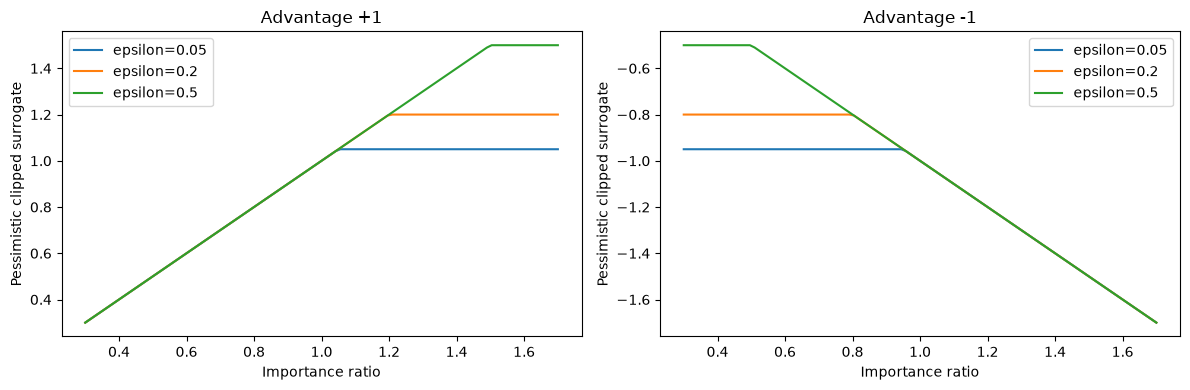

In [2]:
diagnostic_result = diagnostic(2)

## Full experiment commands
Commands fail on errors; required runs are never replaced by fixture diagnostics. Existing run directories are protected from accidental overwrite.

In [3]:
COMMANDS = ['python -m task2_ppo.experiments --mode standard', 'python -m task2_ppo.experiments --mode clipping', 'python -m task2_ppo.experiments --mode kl']
for command in COMMANDS:
    print(command)
if RUN_FULL_EXPERIMENTS:
    for command in COMMANDS:
        args = shlex.split(command)
        args[0] = sys.executable
        subprocess.run(args, cwd=ROOT, check=True)
else:
    print("Full experiment execution is disabled. Set RUN_FULL_EXPERIMENTS=True to run the commands above.")


python -m task2_ppo.experiments --mode standard
python -m task2_ppo.experiments --mode clipping
python -m task2_ppo.experiments --mode kl
Full experiment execution is disabled. Set RUN_FULL_EXPERIMENTS=True to run the commands above.


## Saved course results and examples
Missing results are explicitly reported. Plots use the saved JSON/JSONL logs from actual runs.

In [4]:
from common.visualization import plot_task
plot_task(2)

Course results have not been generated for this task. No course metrics are inferred.
